In [ ]:
import pandas as pd
import numpy as np

!gdown 1ZdhRqYv-JizWV6DxO6C4R_k1kxPhmlF2

Downloading...
From: https://drive.google.com/uc?id=1ZdhRqYv-JizWV6DxO6C4R_k1kxPhmlF2
To: /content/multiclass.csv
100% 14.6k/14.6k [00:00<00:00, 31.0MB/s]


In [ ]:
df=pd.read_csv('multiclass.csv')
df.head()

,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,class
0,3,12669,9656,7561,214,2674,1338,2
1,3,7057,9810,9568,1762,3293,1776,2
2,3,6353,8808,7684,2405,3516,7844,2
3,3,13265,1196,4221,6404,507,1788,1
4,3,22615,5410,7198,3915,1777,5185,1


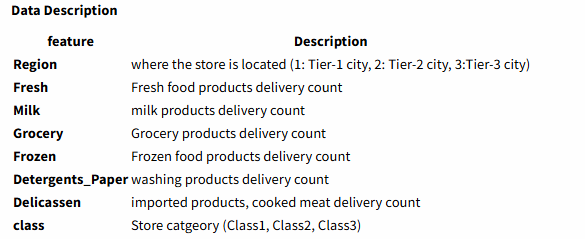

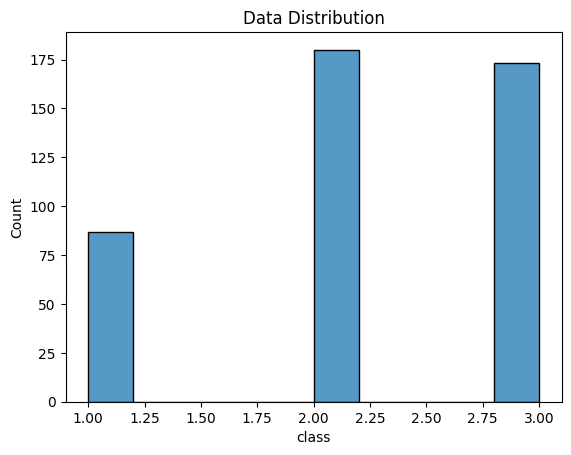

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df, x="class")
plt.title('Data Distribution')
plt.show()

In [ ]:
X=df[['Region',	'Fresh',	'Milk',	'Grocery',	'Frozen',	'Detergents_Paper',	'Delicassen'	]].copy()
y=df[['class']].copy()

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [ ]:
X.shape

(440, 7)

In [ ]:
pca = PCA(n_components=2)
visualize = pca.fit_transform(X)

In [ ]:
visualize.shape

(440, 2)

In [ ]:

def scatter_visualize(visualize1,visualize2,y_label):
  scatter = plt.scatter(visualize[:,0] ,visualize[:,1],c = y.values[:,0] )
  plt.legend(handles=scatter.legend_elements()[0], labels=['Class1','Class2','Class3'])
  plt.show()

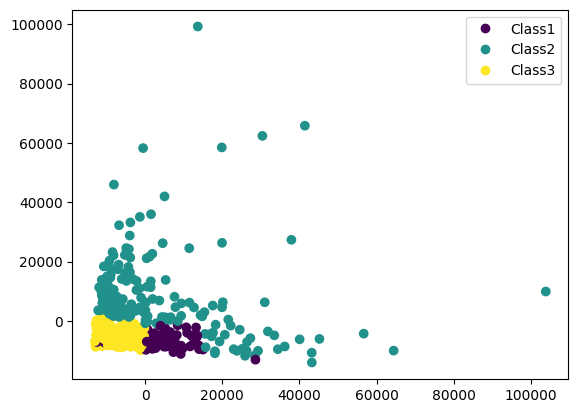

In [ ]:
scatter_visualize(visualize[:,0] ,visualize[:,1],y.values[:,0])

## Lets code KNN From scratch

### First is usual Train, Validation and test split

In [ ]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt


X_train_val, X_test, y_train_val, y_test = train_test_split(X,y,test_size=0.25, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(X_train_val,y_train_val,test_size=0.25, random_state=42)


In [ ]:
print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(247, 7) (247, 1)
(83, 7) (83, 1)
(110, 7) (110, 1)


In [ ]:
from imblearn.over_sampling import SMOTE


# Create an instance of SMOTE
smt = SMOTE()

In [ ]:
X_sm, y_sm = smt.fit_resample(X_train, y_train)

In [ ]:
y_train.value_counts()

,count
class,
3,99
2,95
1,53


In [ ]:
y_sm.value_counts()


,count
class,
1,99
2,99
3,99


In [ ]:
from sklearn.preprocessing import StandardScaler

st =  StandardScaler()

In [ ]:
X_sm = st.fit_transform(X_sm.values)
X_val_scaled = st.transform(X_val.values)
X_test_scaled = st.transform(X_test.values)

In [ ]:
y_sm = y_sm.values[:,0]
y_val = y_val.values[:,0]
y_test = y_test.values[:,0]

In [ ]:
l = [1,2,3,4,5]

In [ ]:
l[2]

3

In [ ]:
X_val_scaled[50]

array([ 0.67469815, -0.59800171, -0.45313604, -0.65996023, -0.28269091,
       -0.5117563 , -0.28368393])

## STep 1 - Distance of xq with all other training points

In [ ]:
X_sm

array([[ 0.67469815,  1.55265042,  1.30678213, ..., -0.48251738,
        -0.57174832, -0.05192486],
       [ 0.67469815,  0.04600414, -0.13287447, ..., -0.51084462,
        -0.52606209,  0.50047468],
       [ 0.67469815,  3.22407775, -0.17960929, ...,  0.48146191,
        -0.34331718, -0.06587894],
       ...,
       [-0.56993135,  1.7469525 ,  1.83030817, ...,  9.40181125,
        -0.30386089,  1.15267623],
       [-1.81456086, -0.95636919,  0.237483  , ..., -0.4903671 ,
         1.42437069,  0.14949924],
       [-0.56993135, -0.91852859,  0.25508858, ..., -0.18576398,
         0.4506541 , -0.06284545]])

In [ ]:
dist = np.sqrt(np.sum((X_sm - X_val_scaled[50])**2, axis=1))

In [ ]:
dist.shape

(297,)

In [ ]:
X_sm.shape

(297, 7)

In [ ]:
# Storing distance and Class labels together
distances = [(dist[i],y_sm[i]) for i in range(len(dist)) ]

In [ ]:
distances = sorted(distances)


In [ ]:
# Nearest/First K points
distances = distances[:5]

In [ ]:
distances

[(np.float64(0.1940865061522643), np.int64(3)),
 (np.float64(0.1981135049522906), np.int64(3)),
 (np.float64(0.22804226913616696), np.int64(3)),
 (np.float64(0.2856714313166793), np.int64(3)),
 (np.float64(0.28643579623470705), np.int64(3))]

In [ ]:
distances = np.array(distances)

In [ ]:
classes_counts = np.unique(distances[:,1],return_counts=True)


In [ ]:
classes_counts

(array([3.]), array([5]))

In [ ]:
index = classes_counts[1].argmax()
pred = classes_counts[0][index]

In [ ]:
y_val[50]

np.int64(3)

In [ ]:
def knn(X,Y,queryPoint,k):
    """Predict the class label for the query point"""
    # Euclidean Distance
    dist = np.sqrt(np.sum((queryPoint-X)**2,axis=1) )

    # Storing distance and Class labels together
    distances = [(dist[i],Y[i]) for i in range(len(dist)) ]
    # sort the distances
    distances = sorted(distances)
    # Nearest/First K points
    distances = distances[:k]

    distances = np.array(distances)

    classes_counts = np.unique(distances[:,1],return_counts=True)

    index = classes_counts[1].argmax()
    pred = classes_counts[0][index]

    return int(pred),distances

In [ ]:
pred,neighbors = knn(X_sm, y_sm, X_val_scaled[50],5)


In [ ]:
print(f'k nearest neighbors with the distance and class label :{neighbors}')

print(f'The predicted class label: {pred}')

k nearest neighbors with the distance and class label :[[0.19408651 3.        ]
 [0.1981135  3.        ]
 [0.22804227 3.        ]
 [0.28567143 3.        ]
 [0.2864358  3.        ]]
The predicted class label: 3


In [ ]:
y_val[50]


np.int64(3)

In [ ]:
pred,neighbors = knn(X_sm, y_sm, X_val_scaled[20],5)

In [ ]:
pred

1

In [ ]:
y_val[20]

np.int64(1)

In [ ]:
X_test_scaled.shape

(110, 7)

In [ ]:
y_pred = []


for i in range(110):
  output,_ = knn(X_sm, y_sm, X_test_scaled[i],5)
  y_pred.append(output)


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test,y_pred)


In [ ]:
cm

array([[16,  2,  2],
       [ 8, 36,  3],
       [ 1,  1, 41]])

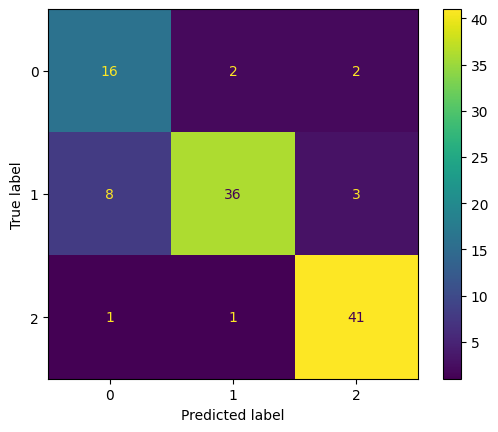

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(cm).plot()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_pred,y_test))



              precision    recall  f1-score   support

           1       0.80      0.64      0.71        25
           2       0.77      0.92      0.84        39
           3       0.95      0.89      0.92        46

    accuracy                           0.85       110
   macro avg       0.84      0.82      0.82       110
weighted avg       0.85      0.85      0.84       110



In [ ]:
from sklearn.neighbors import KNeighborsClassifier


In [ ]:
knn = KNeighborsClassifier(n_neighbors=5,metric='euclidean')


In [ ]:
knn.fit(X_sm, y_sm)


KNeighborsClassifier(metric='euclidean')

In [ ]:
knn.score(X_val_scaled, y_val)


0.8674698795180723

In [ ]:
from sklearn.metrics import classification_report


In [ ]:
y_pred = knn.predict(X_val_scaled)

In [ ]:
print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

           1       0.63      0.86      0.73        14
           2       0.97      0.87      0.92        38
           3       0.90      0.87      0.89        31

    accuracy                           0.87        83
   macro avg       0.83      0.87      0.84        83
weighted avg       0.89      0.87      0.87        83



## Hyperparameter Tune

In [ ]:
Acc = []

for i in range(1,51):
  knn = KNeighborsClassifier(n_neighbors=i,metric='euclidean')
  knn.fit(X_sm, y_sm)


  Acc.append(knn.score(X_val_scaled, y_val))

Text(0, 0.5, 'Accuracy')

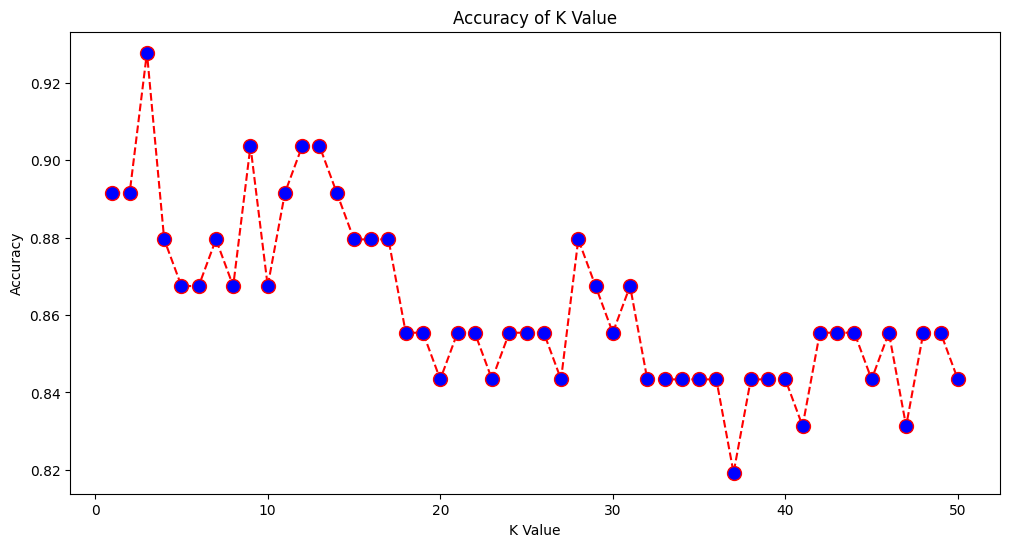

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(range(1, 51), Acc, color='red', linestyle='dashed', marker='o',
         markerfacecolor='blue', markersize=10)
plt.title('Accuracy of K Value')
plt.xlabel('K Value')
plt.ylabel('Accuracy')

In [ ]:
!gdown 1vDIXh1yJxLpmgdh3gZGM6WX0u3GCPuIS


Downloading...
From: https://drive.google.com/uc?id=1vDIXh1yJxLpmgdh3gZGM6WX0u3GCPuIS
To: /content/knn_imputation.csv
100% 12.9k/12.9k [00:00<00:00, 30.6MB/s]


In [ ]:
import pandas as pd
import numpy as np

df_imp = pd.read_csv('knn_imputation.csv')
df_imp.drop(['Unnamed: 0'],axis=1,inplace=True)

df_imp.head()

,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,3.0,12669.0,9656.0,7561.0,214.0,2674.0,1338.0
1,3.0,7057.0,9810.0,9568.0,1762.0,3293.0,1776.0
2,3.0,6353.0,8808.0,NaN,2405.0,3516.0,7844.0
3,3.0,13265.0,1196.0,4221.0,6404.0,507.0,1788.0
4,3.0,22615.0,5410.0,7198.0,3915.0,1777.0,5185.0


In [ ]:
df_imp.isna().sum()

,0
Region,8
Fresh,13
Milk,15
Grocery,9
Frozen,8
Detergents_Paper,10
Delicassen,11


## Pipeline Object

In [ ]:
from sklearn.pipeline import Pipeline

from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

In [ ]:
# Create the pipeline
pipeline = Pipeline([
    ('scaler', StandardScaler()),  # Step 1: StandardScaler for feature scaling
    ('imputer', KNNImputer(n_neighbors=5))  # Step 2: KNNImputer for missing value imputation
])

In [ ]:
X_transformed = pipeline.fit_transform(df_imp)


In [ ]:
X_transformed = pd.DataFrame(X_transformed,columns=df_imp.columns)


In [ ]:
X_transformed.head()


,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.555438,-0.233395,0.187310,-0.319038,-0.554681,-0.272830,-0.175386
1,0.555438,-0.616431,0.204632,-0.139260,-0.281917,-0.165147,-0.051741
2,0.555438,-0.664481,0.091925,0.200717,-0.168617,-0.126353,1.661231
3,0.555438,-0.192716,-0.764292,-0.618222,0.536025,-0.649809,-0.048353
4,0.555438,0.445450,-0.290291,-0.351554,0.097452,-0.428875,0.910606


In [ ]:
X_transformed.isna().sum()


,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


## Homework - Use Mean Imputation and then KNN imputation and check the performance

In [ ]:
check this blog: https://research.google/blog/announcing-scann-efficient-vector-similarity-search/